# LifeGuard-RL XJTU remaining useful life

At cycles **50** and **100**, predict how many more cycles an unseen XJTU cell will last before it reaches the documented **80% SOH** threshold. The notebook compares lifetime medians with small Ridge models and audits unusual charging measurements separately.

1. Attach a Kaggle dataset containing **lifeguard_soh_results.zip** or **lifeguard_soh_validation_results.zip**, plus **XJTU_labels.json** from the BatteryLife **Life labels** folder. A folder with **cycle_quality.csv** and **cycle_features.csv** also works.
2. Run all cells with the CPU runtime. The notebook reuses the exported cycle tables from the SOH study.
3. Download **lifeguard_rul_results.zip** from the notebook output. It contains RUL errors in cycles, predictions, cell splits, and the quality audits.

[BatteryLife v12](https://zenodo.org/records/21149533) · [Original XJTU study](https://pmc.ncbi.nlm.nih.gov/articles/PMC11109204/)

In [55]:
INPUT_ROOT = None
SOH_RESULTS_PATH = None  # Optional path to one SOH ZIP or its extracted folder.
LABEL_PATH = None  # Optional path to the published XJTU label JSON.
OUTPUT_ROOT = None
SEED = 42

from importlib.metadata import version
import json
from pathlib import Path, PurePosixPath
from tempfile import TemporaryDirectory
from zipfile import ZIP_DEFLATED, ZipFile

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

if INPUT_ROOT is None:
    if Path("/kaggle/input").is_dir():
        INPUT_ROOT = "/kaggle/input"
    elif Path.cwd().name == "notebooks":
        INPUT_ROOT = Path.cwd().parent
    else:
        INPUT_ROOT = Path.cwd()
if OUTPUT_ROOT is None:
    OUTPUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd() / "outputs"
INPUT_ROOT = Path(INPUT_ROOT).expanduser().resolve()
OUTPUT_ROOT = Path(OUTPUT_ROOT).expanduser().resolve()
if not INPUT_ROOT.is_dir():
    raise FileNotFoundError(f"Input folder does not exist: {INPUT_ROOT}")

## End-of-life labels and charge-trace checks

A supervised target requires the first measured discharge capacity at or below **1.600 Ah** to agree with the published XJTU label. A cell whose trace ends before that crossing stays in the audit as right-censored. Its follow-up only sets a lower bound on RUL.

The charge check compares the current total Ah, charging duration, and taper duration against the previous ten available readings of the same cell. It uses the median and median absolute deviation with the floors defined below. The check flags unusual readings for review. The charge-history model skips flagged values when building its summaries. The measured discharge capacities used for EOL remain independent of the charge flags.

In [56]:
KEY = ["cell_id", "cycle"]
FIXED_CELLS = {
    f"XJTU_{rate}C_battery-{number}": rate
    for rate, count in ((2, 8), (3, 15))
    for number in range(1, count + 1)
}
PILOT_EOLS = {"XJTU_2C_battery-7": 401, "XJTU_3C_battery-2": 291}
NOMINAL_AH = 2.0
EOL_CAPACITY_AH = 1.6
LANDMARKS = (50, 100)
OUTLIER_CELL = "XJTU_2C_battery-2"
OUTLIER_CYCLE = 390
HISTORY_SIZE = 10
MIN_FLAG_HISTORY = 5
MAD_MULTIPLIER = 6.0
# Floors keep small variations from being flagged when recent readings are nearly identical.
FLAG_FLOORS = {"prefix_charge_ah": 0.08, "charge_duration_s": 120.0, "taper_duration_s": 120.0}
RESULT_ARCHIVES = ("lifeguard_soh_validation_results.zip", "lifeguard_soh_results.zip")


def unique_path(matches, description):
    matches = sorted(set(matches))
    if len(matches) != 1:
        raise ValueError(f"Expected one {description}, found {len(matches)}. Set SOH_RESULTS_PATH or LABEL_PATH.")
    return matches[0]


def locate_inputs(root):
    if SOH_RESULTS_PATH is None:
        result = None
        for filename in RESULT_ARCHIVES:
            matches = list(root.rglob(filename))
            if matches:
                result = unique_path(matches, filename)
                break
        if result is None:
            directories = [
                p.parent for p in root.rglob("cycle_quality.csv")
                if (p.parent / "cycle_features.csv").is_file()
            ]
            result = unique_path(directories, "folder containing both SOH cycle tables")
    else:
        result = Path(SOH_RESULTS_PATH).expanduser().resolve()
    if LABEL_PATH is None:
        labels = unique_path(root.rglob("XJTU_labels.json"), "XJTU_labels.json")
    else:
        labels = Path(LABEL_PATH).expanduser().resolve()
    return result, labels


def load_cycle_tables(results):
    names = ("cycle_quality.csv", "cycle_features.csv")
    if results.is_dir():
        quality, features = (pd.read_csv(results / name) for name in names)
    else:
        with ZipFile(results) as archive:
            frames = []
            for name in names:
                matches = [member for member in archive.namelist() if PurePosixPath(member).name == name]
                member = unique_path(matches, f"{name} inside the SOH results ZIP")
                with archive.open(member) as stream:
                    frames.append(pd.read_csv(stream))
        quality, features = frames

    late_columns = {f"late_taper_{field}": field for field in FLAG_FLOORS}
    if all(field in features.columns for field in late_columns):
        features = features.rename(columns=late_columns)
    quality = quality.loc[:, KEY + ["charge_rate_c", "discharge_capacity_ah"]].copy()
    features = features.loc[:, KEY + list(FLAG_FLOORS)].copy()
    for frame in (quality, features):
        if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
            raise ValueError("The cycle tables must have unique, complete cell and cycle keys.")
    if set(quality.cell_id) != set(FIXED_CELLS) or not quality.charge_rate_c.eq(quality.cell_id.map(FIXED_CELLS)).all():
        raise ValueError("Expected the 23 fixed-protocol XJTU cells and their documented charge rates.")
    joined = features.merge(quality[KEY], on=KEY, how="left", indicator=True, validate="one_to_one")
    if not joined["_merge"].eq("both").all():
        raise ValueError("Every feature row must have a matching quality row.")
    if set(features.cell_id) != set(FIXED_CELLS):
        raise ValueError("Every cell must have some exported late-taper features.")
    quality["measured_soh_pct"] = 100.0 * quality.discharge_capacity_ah / NOMINAL_AH
    return quality.sort_values(KEY).reset_index(drop=True), features.sort_values(KEY).reset_index(drop=True)

In [57]:
def audit_eol(quality, labels):
    records = []
    for cell, frame in quality.groupby("cell_id", sort=True):
        cycles = frame.cycle.to_numpy()
        if not np.array_equal(cycles, np.arange(1, len(frame) + 1)):
            raise ValueError(f"{cell} must have consecutive cycle numbers beginning at 1.")
        capacity = frame.discharge_capacity_ah.to_numpy(dtype=float)
        valid = np.isfinite(capacity) & (capacity > 0)
        last = int(cycles[valid][-1]) if valid.any() else None
        crossings = cycles[valid & (capacity <= EOL_CAPACITY_AH)]
        event = int(crossings[0]) if crossings.size else None
        published = labels.get(f"{cell}.pkl")
        if not isinstance(published, int) or published < 1:
            raise ValueError(f"No valid published label for {cell}.")
        if not valid.all():
            status = "review_missing_discharge_capacity"
        elif event is None:
            status = "right_censored" if published > last else "review_label_without_crossing"
        else:
            status = "observed" if event == published else "review_label_mismatch"
        records.append({
            "cell_id": cell, "charge_rate_c": FIXED_CELLS[cell], "last_observed_cycle": last,
            "observed_eol_cycle": event, "published_eol_cycle": published, "event_status": status,
        })
    result = pd.DataFrame(records)
    for column in ("last_observed_cycle", "observed_eol_cycle"):
        result[column] = result[column].astype("Int64")
    return result


def flag_charge_traces(features):
    by_cell = []
    for _, frame in features.groupby("cell_id", sort=False):
        frame = frame.sort_values("cycle").copy()
        marks = []
        for feature, floor in FLAG_FLOORS.items():
            values = frame[feature]
            valid = np.isfinite(values) & (values.ge(0) if feature == "taper_duration_s" else values.gt(0))
            # The shift keeps the current reading out of its own reference window.
            prior = values.where(valid).shift().rolling(HISTORY_SIZE, min_periods=MIN_FLAG_HISTORY)
            center = prior.median()
            mad = prior.apply(lambda window: np.nanmedian(np.abs(window - np.nanmedian(window))), raw=True)
            limit = (MAD_MULTIPLIER * 1.4826 * mad).clip(lower=floor)
            frame[f"{feature}_prior_median"] = center
            frame[f"{feature}_deviation_limit"] = limit
            flag = f"{feature}_flag"
            frame[flag] = ~valid | (values.sub(center).abs() > limit)
            marks.append(flag)
        frame["trace_flagged"] = frame[marks].any(axis=1)
        frame["reference_ready"] = frame[[f"{k}_prior_median" for k in FLAG_FLOORS]].notna().all(axis=1)
        by_cell.append(frame)
    return pd.concat(by_cell, ignore_index=True)

## What the models can use

Each prediction uses data through the end of its observation cycle. The Ridge models use the nominal charge rate, the median of the first ten readings, the median of the last ten cycles, and the trend over the last twenty cycles. One model uses measured discharge SOH. The other uses cumulative late-taper charge in Ah as a separate measurement. All models are evaluated on the same cell and observation-point pairs.

The simplest baseline uses the training cells' median RUL. A second baseline uses the median for the cell's charge rate. Entire cells are held out in five folds stratified by rate. Ridge settings are chosen in three inner folds using only training cells.

In [58]:
STATS = ["initial_median", "recent_median", "recent_slope"]
MEASURED = [f"measured_{name}" for name in STATS]
CHARGE = [f"charge_{name}" for name in STATS]


def history_features(history, value, landmark):
    history = history.loc[history.cycle <= landmark, ["cycle", value]].dropna()
    quiet = history.loc[history.cycle <= 10, value]
    recent = history.loc[history.cycle > landmark - 10, value]
    trend = history.loc[history.cycle > landmark - 20]
    if len(quiet) < 5 or len(recent) < 5 or len(trend) < 10:
        return None
    x = trend.cycle.to_numpy(dtype=float)
    x = x - x.mean()
    level = trend[value].to_numpy(dtype=float)
    slope = float(np.dot(x, level - level.mean()) / np.dot(x, x))
    return [float(quiet.median()), float(recent.median()), slope]


def make_landmarks(quality, flags, eol, landmarks=LANDMARKS):
    by_cell = {cell: frame for cell, frame in quality.groupby("cell_id")}
    charge = flags.loc[~flags.trace_flagged, KEY + ["prefix_charge_ah"]].copy()
    charge_groups = {cell: frame for cell, frame in charge.groupby("cell_id")}
    complete, audit = [], []
    for cell in eol.itertuples(index=False):
        measured = by_cell[cell.cell_id]
        charged = charge_groups.get(cell.cell_id, charge.iloc[:0])
        for landmark in landmarks:
            row = {"cell_id": cell.cell_id, "charge_rate_c": cell.charge_rate_c, "landmark_cycle": landmark}
            status = cell.event_status
            followup = (
                int(cell.last_observed_cycle) - landmark
                if pd.notna(cell.last_observed_cycle) and cell.last_observed_cycle >= landmark else None
            )
            if cell.event_status == "observed":
                if cell.observed_eol_cycle <= landmark:
                    status = "event_at_or_before_landmark"
                else:
                    discharge = history_features(measured, "measured_soh_pct", landmark)
                    late_charge = history_features(charged, "prefix_charge_ah", landmark)
                    if discharge is None or late_charge is None:
                        status = "insufficient_history"
                    else:
                        status = "eligible"
                        target = int(cell.observed_eol_cycle) - landmark
                        complete.append({
                            **row, **dict(zip(MEASURED, discharge, strict=True)), **dict(zip(CHARGE, late_charge, strict=True)),
                            "observed_rul_cycles": target,
                        })
            audit.append({**row, "event_status": cell.event_status, "landmark_status": status,
                          "observed_followup_cycles": followup})
    return pd.DataFrame(complete), pd.DataFrame(audit)


def check_causal_history():
    cycles = np.arange(1, 61)
    synthetic = pd.DataFrame({
        "cell_id": "test", "cycle": cycles,
        "prefix_charge_ah": np.where(cycles == 40, 1.90, 1.65),
        "charge_duration_s": 2500.0, "taper_duration_s": 600.0,
    })
    full = flag_charge_traces(synthetic)
    prefix = flag_charge_traces(synthetic.loc[synthetic.cycle <= 50])
    assert full.loc[full.cycle == 40, "trace_flagged"].item()
    assert not full.loc[full.cycle == 39, "trace_flagged"].item()
    pd.testing.assert_frame_equal(full.loc[full.cycle <= 50].reset_index(drop=True), prefix)
    values = history_features(full.loc[~full.trace_flagged], "prefix_charge_ah", 50)
    edited = full.copy()
    edited.loc[edited.cycle > 50, "prefix_charge_ah"] = 3.9
    assert values == history_features(edited.loc[~edited.trace_flagged], "prefix_charge_ah", 50)

In [59]:
GLOBAL = "pooled_median"
PROTOCOL = "protocol_median"
RIDGE_MODELS = {"ridge_measured_soh": MEASURED, "ridge_charge_history": CHARGE}
MODELS = (GLOBAL, PROTOCOL, *RIDGE_MODELS)
ALPHAS = (0.1, 1.0, 10.0, 100.0)
TARGET = "observed_rul_cycles"


def make_ridge(alpha):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))


def tune_ridge(train, columns, seed):
    partitioner = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    splits = list(partitioner.split(train, train.charge_rate_c))
    scores = []
    for alpha in ALPHAS:
        errors = []
        for fit_indexes, val_indexes in splits:
            fit_rows = train.iloc[fit_indexes]
            validation = train.iloc[val_indexes]
            model = make_ridge(alpha).fit(fit_rows[columns], fit_rows[TARGET])
            estimate = np.maximum(model.predict(validation[columns]), 0.0)
            errors.extend(np.abs(estimate - validation[TARGET].to_numpy()))
        scores.append((float(np.mean(errors)), alpha))
    return min(scores, key=lambda score: (score[0], -score[1]))


def run_benchmark(landmark_data, eol):
    if landmark_data.empty:
        raise ValueError("No cells have verified EOL and sufficient histories at the landmarks.")
    cells = eol[["cell_id", "charge_rate_c"]].sort_values("cell_id").reset_index(drop=True)
    splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    specs = list(splitter.split(cells, cells.charge_rate_c))
    predictions, split_rows, tuning = [], [], []
    for landmark in LANDMARKS:
        rows = landmark_data.loc[landmark_data.landmark_cycle == landmark]
        if rows.empty:
            raise ValueError(f"No eligible cells at cycle {landmark}. See the EOL and landmark audits.")
        for fold, (train_idx, test_idx) in enumerate(specs, start=1):
            train_cells = set(cells.iloc[train_idx].cell_id)
            test_cells = set(cells.iloc[test_idx].cell_id)
            assert train_cells.isdisjoint(test_cells)
            train = rows.loc[rows.cell_id.isin(train_cells)]
            test = rows.loc[rows.cell_id.isin(test_cells)]
            counts = train.charge_rate_c.value_counts().reindex([2, 3], fill_value=0)
            if (counts < 3).any():
                raise ValueError(f"Cycle {landmark}, fold {fold} needs at least three eligible training cells per rate.")
            for role, frame in (("train", train), ("test", test)):
                split_rows.extend({"landmark_cycle": landmark, "fold": fold, "role": role, "cell_id": cell}
                                  for cell in frame.cell_id)
            if test.empty:
                continue

            def record(name, values):
                result = test[["cell_id", "landmark_cycle", "charge_rate_c", TARGET]].copy()
                result["predicted_rul_cycles"] = values
                result["model"] = name
                result["fold"] = fold
                predictions.append(result)

            record(GLOBAL, float(train[TARGET].median()))
            by_rate = train.groupby("charge_rate_c")[TARGET].median()
            record(PROTOCOL, test.charge_rate_c.map(by_rate).to_numpy())
            for name, history in RIDGE_MODELS.items():
                columns = ["charge_rate_c", *history]
                score, alpha = tune_ridge(train, columns, seed=SEED + landmark + fold)
                tuning.append({"landmark_cycle": landmark, "fold": fold, "model": name, "alpha": alpha,
                               "inner_mae_cycles": score})
                model = make_ridge(alpha).fit(train[columns], train[TARGET])
                record(name, np.maximum(model.predict(test[columns]), 0.0))
        print(f"Cycle {landmark}  {len(rows)} held-out cell predictions per model")
    return pd.concat(predictions, ignore_index=True), pd.DataFrame(split_rows), pd.DataFrame(tuning)


def validate_predictions(landmark_data, predictions, split_rows):
    keys = ["cell_id", "landmark_cycle"]
    assert not landmark_data.duplicated(keys).any()
    expected = pd.MultiIndex.from_frame(landmark_data[keys]).sort_values()
    assert set(predictions.model) == set(MODELS)
    assert np.isfinite(predictions.predicted_rul_cycles).all()
    test = split_rows.loc[split_rows.role == "test", keys + ["fold"]]
    assert not test.duplicated(keys).any()
    train = split_rows.loc[split_rows.role == "train", keys + ["fold"]]
    assert test.merge(train, on=keys + ["fold"]).empty
    for model, frame in predictions.groupby("model"):
        actual = pd.MultiIndex.from_frame(frame[keys]).sort_values()
        assert actual.equals(expected), f"{model} prediction coverage mismatch"
        assert len(frame.merge(test, on=keys + ["fold"], validate="one_to_one")) == len(frame)


def compute_metrics(predictions):
    error = predictions.predicted_rul_cycles - predictions[TARGET]
    errors = predictions.assign(error_cycles=error, absolute_error_cycles=error.abs())
    records = []
    for (landmark, model), values in errors.groupby(["landmark_cycle", "model"]):
        groups = [("all", values), *((f"{rate}C", cells) for rate, cells in values.groupby("charge_rate_c"))]
        for rate_group, frame in groups:
            worst = frame.loc[frame.absolute_error_cycles.idxmax()]
            records.append({
                "landmark_cycle": landmark, "group": rate_group, "model": model, "n_cells": len(frame),
                "mae_cycles": frame.absolute_error_cycles.mean(),
                "rmse_cycles": np.sqrt(frame.error_cycles.pow(2).mean()),
                "bias_cycles": frame.error_cycles.mean(), "worst_error_cycles": worst.absolute_error_cycles,
                "worst_cell": worst.cell_id,
            })
    metrics = pd.DataFrame(records).sort_values(["landmark_cycle", "group", "mae_cycles", "model"])
    return errors, metrics

In [60]:
def write_summary(path, eol, flags, eligible, metrics, landmark_audit):
    status_counts = eol.event_status.value_counts()
    lines = [
        "# LifeGuard-RL XJTU remaining useful life",
        "",
        f"**{len(eol)} cells** audited. **{status_counts.get('observed', 0)}** have a verified 80% SOH crossing.",
        "",
        "Remaining useful life (RUL) is the number of cycles between the observation point and the first documented "
        "crossing at or below 80% SOH. Each model only sees history through the observation point.",
        "",
    ]
    excluded = eol[eol.event_status != "observed"]
    for row in excluded.itertuples(index=False):
        extra = ""
        if row.event_status == "right_censored":
            extra = f" Capacity remained above the threshold through cycle {row.last_observed_cycle}."
        lines.append(
            f"- {row.cell_id} excluded from supervised scoring with status {row.event_status.replace('_', ' ')}."
            + extra
            + f" Published label {row.published_eol_cycle}."
        )
    missing = landmark_audit[landmark_audit.landmark_status == "insufficient_history"]
    if len(missing):
        lines.append(f"- {len(missing)} cell and observation-point pairs lacked enough history for a matched comparison.")
    flagged = int(flags.trace_flagged.sum())
    known = flags.loc[(flags.cell_id == OUTLIER_CELL) & (flags.cycle == OUTLIER_CYCLE)]
    if known.empty:
        outlier_note = f"The charge export has no row for cycle {OUTLIER_CYCLE} of {OUTLIER_CELL}."
    else:
        record = known.iloc[0]
        reasons = [feature.replace("_", " ") for feature in FLAG_FLOORS if record[f"{feature}_flag"]]
        outlier_note = (
            f"Cycle {OUTLIER_CYCLE} of {OUTLIER_CELL} was flagged for {', '.join(reasons)}."
            if reasons else f"Cycle {OUTLIER_CYCLE} of {OUTLIER_CELL} passed the configured charge checks."
        )
    lines.extend([
        "",
        f"**{flagged:,} of {len(flags):,}** charge rows flagged. {outlier_note}",
        "",
        "Charge history features skip flagged readings. Measured-capacity histories and EOL checks use the discharge measurements.",
        "",
        "| Observation cycle | Model | Held-out cells | MAE (cycles) | RMSE (cycles) | Worst error (cycles) |",
        "| ---: | --- | ---: | ---: | ---: | ---: |",
    ])
    overall = metrics[metrics.group == "all"]
    for row in overall.itertuples(index=False):
        lines.append(
            f"| {row.landmark_cycle} | {row.model} | {row.n_cells} | {row.mae_cycles:.2f} | "
            f"{row.rmse_cycles:.2f} | {row.worst_error_cycles:.2f} |"
        )
    lines.extend([
        "",
        "Each XJTU cell is held out entirely. The protocol median is the reference for deciding whether measured or charge-derived histories add predictive value. Compare per-rate errors in the metrics CSV.",
        "",
        f"Both charge rates are represented in training and testing. This comparison contains {eligible.cell_id.nunique()} "
        "independent scored cells from one battery design.",
        "",
    ])
    path.write_text("\n".join(lines), encoding="utf-8")


def plot_rul(metrics, predictions, output):
    fig, axes = plt.subplots(1, len(LANDMARKS), figsize=(10, 4.2), layout="constrained")
    for landmark, ax in zip(LANDMARKS, axes, strict=True):
        ranking = metrics[(metrics.landmark_cycle == landmark) & (metrics.group == "all")]
        best = ranking.iloc[0].model
        selection = predictions[(predictions.landmark_cycle == landmark) & (predictions.model == best)]
        for rate, values in selection.groupby("charge_rate_c"):
            ax.scatter(values[TARGET], values.predicted_rul_cycles, label=f"{rate}C", alpha=0.8)
        low = min(selection[TARGET].min(), selection.predicted_rul_cycles.min())
        high = max(selection[TARGET].max(), selection.predicted_rul_cycles.max())
        ax.plot([low, high], [low, high], color="gray", linestyle="--")
        ax.set(title=f"Cycle {landmark}\n{best.replace('_', ' ')}", xlabel="Observed RUL (cycles)",
               ylabel="Predicted RUL (cycles)")
        ax.legend()
        ax.grid(alpha=0.2)
    fig.savefig(output, dpi=150)
    plt.close(fig)


def package_results(output, destination):
    staged = output.parent / "rul_pending.zip"
    with ZipFile(staged, "w", compression=ZIP_DEFLATED) as archive:
        for file in sorted(output.iterdir()):
            if file.is_file():
                archive.write(file, arcname=file.name)
    staged.replace(destination)

Using cycle tables from /kaggle/input/datasets/sakibrayhanyeasin/result
Cycle 50  22 held-out cell predictions per model
Cycle 100  22 held-out cell predictions per model


# LifeGuard-RL XJTU remaining useful life

**23 cells** audited. **22** have a verified 80% SOH crossing.

Remaining useful life (RUL) is the number of cycles between the observation point and the first documented crossing at or below 80% SOH. Each model only sees history through the observation point.

- XJTU_2C_battery-4 excluded from supervised scoring with status right censored. Capacity remained above the threshold through cycle 395. Published label 396.

**1 of 6,937** charge rows flagged. Cycle 390 of XJTU_2C_battery-2 was flagged for prefix charge ah, charge duration s, taper duration s.

Charge history features skip flagged readings. Measured-capacity histories and EOL checks use the discharge measurements.

| Observation cycle | Model | Held-out cells | MAE (cycles) | RMSE (cycles) | Worst error (cycles) |
| ---: | --- | ---: | ---: | ---: | ---: |
| 50 | ridge_charge_history | 22 | 21.01 | 26.84 | 58.67 |
| 50 | ridge_measured_soh | 22 | 22.09 | 28.50 | 65.40 |
| 50 | protocol_median | 22 | 41.25 | 61.93 | 155.50 |
| 50 | pooled_median | 22 | 74.73 | 90.95 | 168.00 |
| 100 | ridge_charge_history | 22 | 19.73 | 24.14 | 52.85 |
| 100 | ridge_measured_soh | 22 | 20.99 | 25.58 | 54.24 |
| 100 | protocol_median | 22 | 41.25 | 61.93 | 155.50 |
| 100 | pooled_median | 22 | 74.73 | 90.95 | 168.00 |

Each XJTU cell is held out entirely. The protocol median is the reference for deciding whether measured or charge-derived histories add predictive value. Compare per-rate errors in the metrics CSV.

Both charge rates are represented in training and testing. This comparison contains 22 independent scored cells from one battery design.


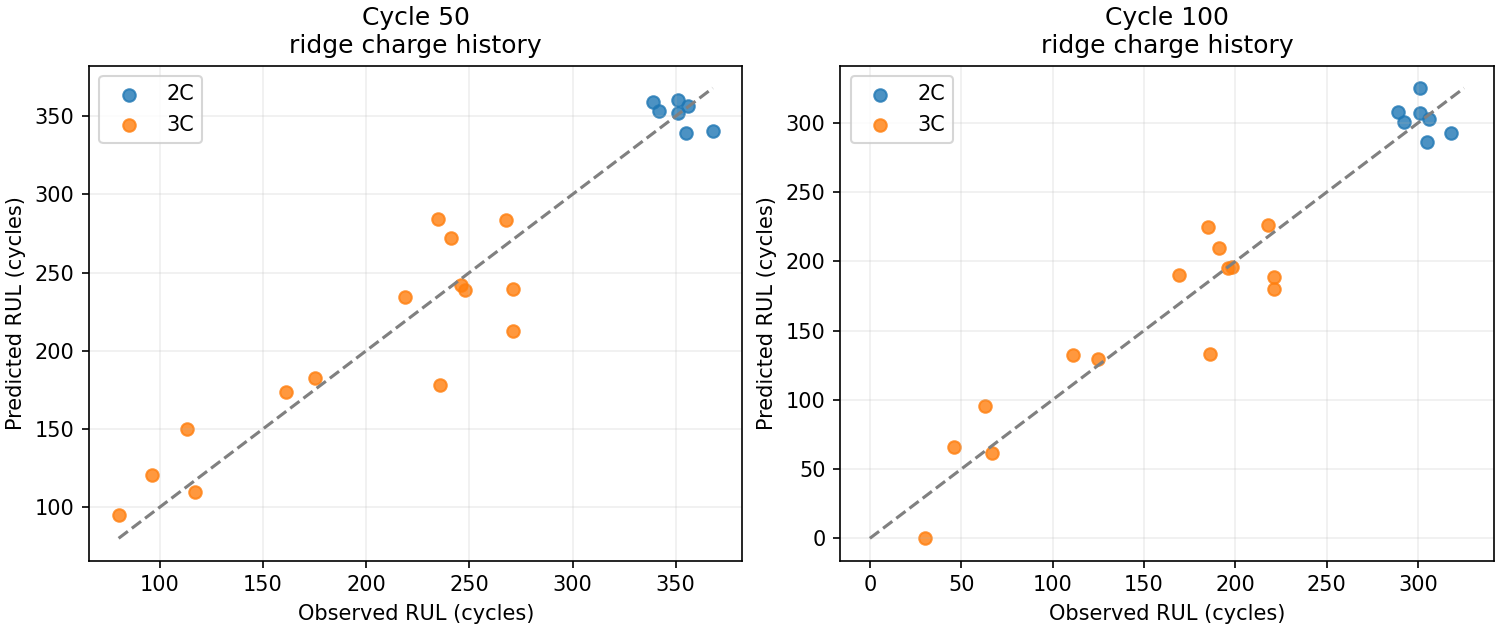

Download lifeguard_rul_results.zip from the notebook output.


In [61]:
check_causal_history()
soh_path, label_path = locate_inputs(INPUT_ROOT)
print(f"Using cycle tables from {soh_path}")
quality, features = load_cycle_tables(soh_path)
labels = json.loads(label_path.read_text(encoding="utf-8"))
eol = audit_eol(quality, labels)
pilots = eol.set_index("cell_id").loc[list(PILOT_EOLS)]
assert pilots.event_status.eq("observed").all()
assert pilots.observed_eol_cycle.to_dict() == PILOT_EOLS
flags = flag_charge_traces(features)
eligible, landmark_audit = make_landmarks(quality, flags, eol)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
destination = OUTPUT_ROOT / "lifeguard_rul_results.zip"
config = {
    "dataset": "BatteryLife v12", "dataset_doi": "10.5281/zenodo.21149533",
    "soh_input": soh_path.name, "landmarks": list(LANDMARKS), "seed": SEED,
    "nominal_capacity_ah": NOMINAL_AH, "eol_capacity_ah": EOL_CAPACITY_AH,
    "charge_flag_prior_readings": HISTORY_SIZE, "charge_flag_min_history": MIN_FLAG_HISTORY,
    "charge_flag_mad_multiplier": MAD_MULTIPLIER, "charge_flag_floors": FLAG_FLOORS,
    "ridge_alphas": list(ALPHAS),
    "packages": {pkg: version(pkg) for pkg in ("numpy", "pandas", "scikit-learn", "matplotlib")},
}

with threadpool_limits(limits=1):
    predictions, splits, tuning = run_benchmark(eligible, eol)
validate_predictions(eligible, predictions, splits)
predictions, metrics = compute_metrics(predictions)
with TemporaryDirectory(prefix="lifeguard_rul_", dir=OUTPUT_ROOT) as directory:
    output = Path(directory) / "results"
    output.mkdir()
    for filename, table in (
        ("eol_audit.csv", eol), ("charge_trace_flags.csv", flags), ("landmark_audit.csv", landmark_audit),
        ("landmark_features.csv", eligible), ("rul_predictions.csv", predictions), ("rul_metrics.csv", metrics),
        ("cell_splits.csv", splits), ("ridge_parameters.csv", tuning),
    ):
        table.to_csv(output / filename, index=False)
    (output / "run_config.json").write_text(json.dumps(config, indent=2) + "\n", encoding="utf-8")
    write_summary(output / "summary.md", eol, flags, eligible, metrics, landmark_audit)
    plot_rul(metrics, predictions, output / "rul_predictions.png")
    package_results(output, destination)
    display(Markdown((output / "summary.md").read_text(encoding="utf-8")))
    display(Image(filename=str(output / "rul_predictions.png")))
print(f"Download {destination.name} from the notebook output.")